# Recurring clusters of worry and reported harm across World Risk Poll waves

## The paper's scientific narrative

We fitted each survey wave independently. We retained every setting that passed
its within-wave size and stability tests, then asked which acceptable models
corroborated across waves. **2025 is the reference wave for reporting and cluster
correspondence.** The subsequent cross-wave selection is joint development
selection, distinct from independently choosing a winner inside each wave.

The principal full solution has **seven clusters in 2021, 2023 and 2025**, using
six worries and all fourteen personal/known-person harm indicators. Its original
point partitions agree closely. Repeated fitting supports four stronger recurring
clusters and more variable traffic, crime and weather divisions. A complementary
five-worry solution has **three exactly identical point clusters in the later
waves**. We did not find a comparably robust shared partition including 2019.

Other passing settings are within-wave suitable alternatives. The original frozen
2025 six-cluster benchmark and 2023 WARM-5/T5 remain unchanged archival models.
Their held-out findings belong to those models. The later jointly selected
solutions have development-based cross-wave corroboration, without a new held-out
assessment.

This is one complete editable analytical notebook. It includes preprocessing,
weighted fitting, subsampling, the complete candidate catalogue, every acceptance
decision, exhaustive Boolean description code, cross-wave comparison, fixed-model
frequencies, country summaries, figures and saved results. It imports only the
usual scientific Python libraries and the standard library, with no project
source helpers or specialist optimizer.

**Run All fits no clustering.** It reconstructs results from readable model
centres and aggregate answer patterns, verifies every retained rule, reconstructs
all point comparisons and the principal conditional refit distributions, and
writes the displayed tables and figures to `results/`. Expensive fitting and rule
regeneration remain off. Survey records and respondent-linked assignments are
not distributed. The original surveys can be supplied separately for new fitting.

The older 2023 predictive experiments are a labelled research archive outside
this notebook. They use additional model libraries and are not silently replaced
by different models here.

In [2]:
from pathlib import Path
from itertools import combinations, product
from collections import Counter
from datetime import datetime
from math import comb
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from threadpoolctl import threadpool_limits
from IPython.display import display

HERE = next((p for p in [Path('.'), Path('paper'), Path('github_publication/paper')]
             if (p/'assets/models.json').is_file()), None)
assert HERE is not None, 'Keep the notebook beside its assets folder.'
ASSETS = HERE/'assets'
RESULTS = HERE/'results'
RESULTS.mkdir(exist_ok=True)
RECALCULATE_DISTRIBUTIONS = True   # About one minute. Reuses saved fits, without training.
VERIFY_ALL_CONFIRMATION_CENTRES = False
REGENERATE_RULES = False          # Exhaustive, potentially expensive.
REFIT_CANDIDATE_CATALOGUE = False  # Thousands of fits; requires separately supplied surveys.
REBUILD_COUNTRY_AGGREGATES = False
FAMILIES = {'full':[2021,2023,2025], 'common_worry':[2019,2021,2023,2025]}
DOMAINS = ['food','water','crime','severe_weather','traffic','mental_health']
HARM_DOMAINS = DOMAINS + ['work']
FULL_NAMES = {0:'Traffic worry',1:'Water/food worry',2:'Crime worry',3:'Severe-weather worry',
              4:'Mental-health worry',5:'Broad known-person harm',6:'Lower severe worry'}
WORRY_NAMES = {0:'Crime worry without water worry',1:'Crime and water worry',2:'No crime worry'}
models = json.loads((ASSETS/'models.json').read_text())
primary = {f:{int(y):t for y,t in v.items()} for f,v in
           json.loads((ASSETS/'primary_models.json').read_text()).items()}
manifest = json.loads((ASSETS/'manifest.json').read_text())
for name,digest in manifest['files_sha256'].items():
    assert hashlib.sha256((ASSETS/name).read_bytes()).hexdigest()==digest, name


def model_key(model):
    return f'{model["family"]}__{model["scope"]}__{model["year"]}__{model["trial"]}'


def find_model(family, year, trial=None, scope='original'):
    trial = primary[family][year] if trial is None else trial
    return next(m for m in models if m['family']==family and m['scope']==scope
                and m['year']==year and m['trial']==trial)


def read_npz(name):
    with np.load(ASSETS/name, allow_pickle=False) as saved:
        return {key:saved[key] for key in saved.files}

native = {(f,y):read_npz(f'native_{f}_{y}.npz') for f,years in FAMILIES.items() for y in years}
references = {f:read_npz(f'reference_{f}.npz') for f in FAMILIES}
eligibility = pd.read_csv(ASSETS/'eligibility.csv')
display(eligibility)

,family,wave,development_countries,development_respondents,eligible,excluded
0,full,2021,96,99870,93548,6322
1,full,2023,113,116820,109488,7332
2,full,2025,111,114399,107507,6892
3,common_worry,2019,114,124074,114428,9646
4,common_worry,2021,96,99870,96196,3674
5,common_worry,2023,113,116820,112753,4067
6,common_worry,2025,111,114399,110436,3963


## 1. Comparable inputs, eligibility and weights

The full family uses food, water, crime, severe-weather, traffic and mental-health
worry, plus seven personal and seven known-person harm indicators, including work.
The five-worry family excludes traffic and every harm input, allowing 2019 to be
included. These are two different clustering problems.

Source worry codes 1/2/3 mean very/somewhat/not worried. We recode them to 2/1/0.
For each original harm question, personal only gives (1,0), known-person only
(0,1), both (1,1), and neither (0,0). The first indicator concerns the respondent;
the second concerns someone personally known. Missing, unknown and refused
answers stay missing. We retain complete answers for the relevant input family,
without imputation. Eligibility therefore differs by family and wave.

For respondent $i$ in country $c$ and wave $y$, let
$w_i=WGT_i/(C\sum_{j\in(c,y)}WGT_j)$ within the eligible population. Every included
country has mass $1/C$, while relative survey weights are preserved within it.
Recalculate these weights after subsampling. These are equal-country summaries,
not world-population shares.

The public arrays aggregate identical original-answer patterns. `counts` records
respondent frequencies and `mass` records weighted mass. The full input order is
six worries, seven personal indicators, seven known-person indicators. The rule
catalogue uses another explicitly converted order. No public array contains
respondent IDs, row-linked weights or a row-to-country registry.

In [3]:
def country_weights(frame):
    return (frame.WGT/frame.groupby('COUNTRY_ISO3').WGT.transform('sum')
            /frame.COUNTRY_ISO3.nunique()).to_numpy()


def recode_survey(raw, family, year):
    worry_sources = (['L6A','L6B','L6C','L6D','L6G'] if year==2019 else
                     ['WP20720','WP20721','WP20722','WP20723'] +
                     (['WP22213'] if family=='full' else []) + ['WP20726'])
    if family=='full':
        assert year!=2019, '2019 does not provide this full representation.'
    worry = raw[worry_sources].apply(lambda s:s.map({1:2.,2:1.,3:0.})).to_numpy()
    if family=='full':
        harm_sources = [f'WP224{x}' for x in range(42,49)]
        personal = raw[harm_sources].apply(lambda s:s.map({1:1.,2:0.,3:1.,4:0.})).to_numpy()
        known = raw[harm_sources].apply(lambda s:s.map({1:0.,2:1.,3:1.,4:0.})).to_numpy()
        answers = np.column_stack([worry,personal,known])
    else:
        answers = worry
    eligible = np.isfinite(answers).all(1)
    frame = raw.loc[eligible].reset_index(drop=True)
    assert np.isfinite(frame.WGT).all() and frame.WGT.gt(0).all()
    return frame, answers[eligible].astype('int8')


def aggregate_patterns(frame, answers):
    patterns, inverse = np.unique(answers,axis=0,return_inverse=True)
    return dict(answers=patterns,counts=np.bincount(inverse),
                mass=np.bincount(inverse,weights=country_weights(frame)))


for (family,year),pack in native.items():
    expected = eligibility.loc[eligibility.family.eq(family)&eligibility.wave.eq(year)].iloc[0]
    assert pack['counts'].sum()==expected.eligible
    np.testing.assert_allclose(pack['mass'].sum(),1.,atol=1e-12,rtol=0)
    assert pack['answers'].shape[1]==(20 if family=='full' else 5)
    assert np.isin(pack['answers'][:,:6 if family=='full' else 5],[0,1,2]).all()
print('Seven native development populations verified. Survey preprocessing is explicit above.')

Seven native development populations verified. Survey preprocessing is explicit above.


## 2. Representation, stored centres and assignment

For a model's own $q$, convert not/somewhat/very worry to $0,q,1$. Let $m$ be
its respondent mean. Full models use
$z=[\sqrt{\alpha/6}(x-m\mathbf1),\sqrt{\alpha/6}m,
\sqrt{(1-\alpha)/14}h]$, with all fourteen harm indicators $h$.
Worry-only models use $[x-m\mathbf1,m]/\sqrt5$. There is no variance scaling,
imputation or respondent-level PCA. The mean is derived, not an extra answer.

Weighted K-means minimizes $\sum_iw_i\min_c\|z_i-\mu_c\|^2$. Assignment uses the
nearest stored centre. The first stored centre resolves an exact distance tie.
Each wave has its own representation and independently fitted centres. Numeric
IDs remain local. A later maximum-overlap correspondence maps them to the 2025
reference IDs without changing the stored model.

In [4]:
def matrix(answers, model, family):
    n = 6 if family == 'full' else 5
    worry = np.where(answers[:,:n] == 2, 1., np.where(answers[:,:n] == 1, model['q'], 0.))
    mean = worry.mean(1, keepdims=True)
    if family == 'common_worry':
        return np.column_stack([worry-mean, mean])/np.sqrt(5)
    alpha = model['alpha']
    return np.column_stack([(worry-mean)*np.sqrt(alpha/6), mean*np.sqrt(alpha/6),
                            answers[:,n:]*np.sqrt((1-alpha)/14)])

In [5]:
native_predictions = {}
reference_predictions = {}
expected_predictions = read_npz('reference_predictions.npz')
for model in models:
    family,year = model['family'],model['year']
    labels = cdist(matrix(references[family]['answers'],model,family),model['centres']).argmin(1).astype('int8')
    np.testing.assert_array_equal(labels,expected_predictions[model_key(model)])
    reference_predictions[model_key(model)] = labels
    if model['scope']=='original':
        pack = native[family,year]
        native_predictions[model_key(model)] = cdist(matrix(pack['answers'],model,family),model['centres']).argmin(1).astype('int8')
print('All 94 original/sensitivity model definitions replay on the fixed references.')

All 94 original/sensitivity model definitions replay on the fixed references.


## 3. Within-wave suitability defines the acceptable set

The original pilot search considered $k=3,\ldots,10$, worry coding and, for full
models, worry--harm allocation. It used grid points, nearby midpoints and twenty
adaptive TPE proposals per $k$. TPE is a standard sequential optimizer. The
complete original proposal values and pilot scores are supplied as data. Keeping
those proposals as data avoids a specialist optimization dependency. The optional
code later re-evaluates this entire finite catalogue; it does **not** claim to
regenerate Optuna's historical proposal stream or the platform's exact random fits.

Rank completed structurally eligible pilots by weaker p10 ARI, weaker median,
distance to the central coding/allocation, then parameter order. Fix two settings
per $k$ before confirmation. Full 2023 also retained two declared historical
settings. Thus full confirmation considered 16/18/16 settings in 2021/2023/2025,
not merely that many K-means runs. Worry-only confirmation considered sixteen
settings per wave. Each setting's two tests had fifty fresh refits.

A confirmed setting passes when all clusters are present, largest weighted share
is at most 40%, $k$ times that share is below 3, and **both median and p10 ARI
are at least 0.80 in both tests**. Cluster-wise Jaccard is a separate diagnostic,
without a new acceptance cutoff. Keep every passing setting, including multiple
settings at one $k$. This gives 31 full settings and 16 worry-only settings.

In [6]:
confirmation = pd.read_csv(ASSETS/'all_confirmation_results.csv',float_precision='round_trip')
catalogue = pd.read_csv(ASSETS/'historical_candidate_catalogue.csv',float_precision='round_trip')
quality_columns = ['respondents_median','respondents_p10','countries_median','countries_p10']
keep = (confirmation.status.eq('complete') & confirmation.structural_pass
        & confirmation.largest_share.le(.4) & confirmation.dominance.lt(3)
        & confirmation[quality_columns].ge(.8).all(axis=1))
accepted = confirmation.loc[keep].copy()
expected = pd.read_csv(ASSETS/'accepted_settings.csv')
assert set(zip(accepted.family,accepted.wave,accepted.trial))==set(zip(expected.family,expected.wave,expected.trial))
assert accepted.groupby('family').size().to_dict()=={'common_worry':16,'full':31}
accepted['paper_primary'] = [r.family in primary and r.wave!=2019 and
                           primary[r.family][r.wave]==r.trial for r in accepted.itertuples()]
summary = accepted.groupby(['family','wave']).agg(settings=('trial','size'),
    cluster_descriptions=('k','sum'),passing_k=('k',lambda x:', '.join(map(str,sorted(set(x)))))).reset_index()
display(summary)
display(accepted[['family','wave','trial','k','q','alpha','respondents_p10','countries_p10','paper_primary']]
        .sort_values(['family','wave','k','trial']).round(4))

,family,wave,settings,cluster_descriptions,passing_k
0,common_worry,2019,9,55,"3, 5, 6, 7, 10"
1,common_worry,2021,2,6,3
2,common_worry,2023,3,16,"3, 10"
3,common_worry,2025,2,6,3
4,full,2021,9,51,"3, 4, 5, 6, 7, 8"
5,full,2023,13,76,"3, 4, 5, 6, 7, 8, 9"
6,full,2025,9,49,"3, 4, 5, 6, 7, 8"


,family,wave,trial,k,q,alpha,respondents_p10,countries_p10,paper_primary
99,common_worry,2019,k3_4227f8b3737afcdb,3,0.4967,NaN,0.9292,0.9292,False
98,common_worry,2019,k3_e3f2e3465c263ff4,3,0.4701,NaN,0.9857,0.9604,False
102,common_worry,2019,k5_13b0da29ee255a33,5,0.3426,NaN,0.8631,0.8430,False
103,common_worry,2019,k5_fa67893bed414dae,5,0.2896,NaN,0.8659,0.8393,False
105,common_worry,2019,k6_020206858ec8975b,6,0.3511,NaN,0.8133,0.8077,False
104,common_worry,2019,k6_7b55ffef0898d3ec,6,0.2862,NaN,0.8197,0.8257,False
106,common_worry,2019,k7_dc89ec04de398ed7,7,0.2248,NaN,0.8212,0.8221,False
112,common_worry,2019,k10_20ef728c9e961c1d,10,0.7960,NaN,0.8054,0.8013,False
113,common_worry,2019,k10_6ecc92a380daf43f,10,0.7000,NaN,0.8150,0.8134,False
83,common_worry,2021,k3_954cad7dc75698bc,3,0.7475,NaN,1.0000,1.0000,True


## 4. Descriptions in original response units

Names summarize characteristic combinations of answers. They do not require
every cluster member to satisfy the same verbal condition. Calculate within-
cluster category probabilities and weighted shares from the original answers.
Every model uses its own complete development population here. The cross-wave
comparison in the next section instead fixes a common reference population.

In [7]:
def describe_patterns(pack, labels, model):
    rows=[]
    n=6 if model['family']=='full' else 5
    for cluster in range(model['k']):
        member=labels==cluster
        total=pack['mass'][member].sum()
        for j in range(pack['answers'].shape[1]):
            for answer in range(3 if j<n else 2):
                rows.append(dict(family=model['family'],wave=model['year'],trial=model['trial'],
                    cluster=cluster,feature=j,answer=answer,
                    probability=pack['mass'][member&(pack['answers'][:,j]==answer)].sum()/total,
                    share=total,respondents=int(pack['counts'][member].sum())))
    return pd.DataFrame(rows)


native_descriptions=pd.concat([describe_patterns(native[m['family'],m['year']],
    native_predictions[model_key(m)],m) for m in models if m['scope']=='original'],ignore_index=True)
old=pd.read_csv(ASSETS/'expected_native_descriptions.csv',float_precision='round_trip')
keys=['family','wave','trial','cluster','feature','answer']
check=native_descriptions.merge(old,on=keys,validate='1:1',suffixes=('_new','_saved'))
np.testing.assert_allclose(check.probability_new,check.probability_saved,atol=1e-12,rtol=0)
np.testing.assert_allclose(check.share_new,check.share_saved,atol=1e-12,rtol=0)
print('All original-answer distributions reconstructed for all 259 clusters.')

All original-answer distributions reconstructed for all 259 clusters.


## 5. Comparable references and partition metrics

The full reference contains 270,808 respondents in 92 development countries shared
by 2021/2023/2025. The five-worry reference contains 365,561 in 90 countries shared
by all four waves. Every compared model assigns the **same reference answers**.
This compares learned assignment functions, without linking individuals over time.

Ordinary ARI uses respondent counts and is invariant to label permutations. It
is not percentage accuracy. Weighted overlap, one-to-one agreement and Jaccard
use equal-country/survey masses. Pooled masses average wave-specific masses;
pooled ARI sums respondent counts. Report each reference wave and the pool; the
primary reporting reference is 2025.

For weighted joint proportions $p_{ab}$, conditional entropy in bits is
$H(A\mid B)=-\sum_{ab}p_{ab}\log_2(p_{ab}/p_{+b})$. Zero means B refines A on this
population. Both directions zero mean equal partitions up to labels. Variation
of information is their sum. Many-to-one purity permits merging clusters and
is more permissive than one-to-one agreement.

In [8]:
def metrics(a, b, counts, weights, ka, kb):
    cells = a.astype(int)*kb+b
    n = np.bincount(cells, weights=counts, minlength=ka*kb).reshape(ka,kb)
    choose = lambda x: x*(x-1)/2
    rows, cols = choose(n.sum(1)).sum(), choose(n.sum(0)).sum()
    expected = rows*cols/choose(n.sum())
    denominator = .5*(rows+cols)-expected
    ari = (choose(n).sum()-expected)/denominator if denominator else 1.
    p = np.bincount(cells,weights=weights,minlength=ka*kb).reshape(ka,kb)
    p /= p.sum()
    entropy = lambda x: -np.sum(x[x>0]*np.log2(x[x>0]))
    ha,hb,hab = entropy(p.sum(1)),entropy(p.sum(0)),entropy(p)
    ra,cb = linear_sum_assignment(-p)
    j = p[ra,cb]/(p.sum(1)[ra]+p.sum(0)[cb]-p[ra,cb])
    return dict(ARI=float(ari),weighted_agreement=float(p[ra,cb].sum()),
        H_A_given_B=max(0.,float(hab-hb)),H_B_given_A=max(0.,float(hab-ha)),
        VI=max(0.,float(2*hab-ha-hb)),B_to_A_purity=float(p.max(0).sum()),
        A_to_B_purity=float(p.max(1).sum()),weakest_matched_Jaccard=float(j.min()))

In [9]:
point_rows=[]
for family,years in FAMILIES.items():
    pack=references[family]
    populations=[(str(y),pack['counts'][i],pack['masses'][i]) for i,y in enumerate(years)]
    populations.append(('pooled',pack['counts'].sum(0),pack['masses'].mean(0)))
    for scope in ['original','common_refit']:
        entries=[m for m in models if m['family']==family and m['scope']==scope]
        for a,b in combinations(entries,2):
            if a['year']==b['year']:continue
            if a['year']>b['year']:a,b=b,a
            for evaluation,counts,mass in populations:
                point_rows.append(dict(family=family,scope=scope,year_a=a['year'],year_b=b['year'],
                    trial_a=a['trial'],trial_b=b['trial'],k_a=a['k'],k_b=b['k'],evaluation=evaluation,
                    **metrics(reference_predictions[model_key(a)],reference_predictions[model_key(b)],
                              counts,mass,a['k'],b['k'])))
all_pairs=pd.DataFrame(point_rows)
old=pd.read_csv(ASSETS/'expected_all_candidate_pairs.csv',float_precision='round_trip')
keys=['family','scope','year_a','year_b','trial_a','trial_b','evaluation']
check=all_pairs.merge(old,on=keys,validate='1:1',suffixes=('_new','_saved'))
assert len(check)==len(all_pairs)==3310
for column in ['ARI','weighted_agreement','H_A_given_B','H_B_given_A','VI']:
    np.testing.assert_allclose(check[column+'_new'],check[column+'_saved'],atol=1e-12,rtol=0)
# Two independent numerical checks, and a toy exact refinement.
for row in all_pairs.iloc[::150].itertuples():
    a=find_model(row.family,row.year_a,row.trial_a,row.scope)
    b=find_model(row.family,row.year_b,row.trial_b,row.scope)
    x=reference_predictions[model_key(a)];y=reference_predictions[model_key(b)];pack=references[row.family]
    i=FAMILIES[row.family].index(2025)
    if row.evaluation=='2025':
        np.testing.assert_allclose(adjusted_rand_score(np.repeat(x,pack['counts'][i]),
            np.repeat(y,pack['counts'][i])),row.ARI,atol=1e-12,rtol=0)
    mass=pack['masses'].mean(0) if row.evaluation=='pooled' else pack['masses'][FAMILIES[row.family].index(int(row.evaluation))]
    cross=np.bincount(x.astype(int)*b['k']+y,weights=mass,minlength=a['k']*b['k']).reshape(a['k'],b['k'])
    direct=-sum(cross[u,v]*np.log2(cross[u,v]/cross[:,v].sum())
        for u in range(a['k']) for v in range(b['k']) if cross[u,v]>0)
    np.testing.assert_allclose(direct,row.H_A_given_B,atol=1e-12,rtol=0)
toy=metrics(np.array([0,0,1,1]),np.arange(4),np.ones(4),np.ones(4)/4,2,4)
assert toy['H_A_given_B']==0 and toy['H_B_given_A']==1
print('All 3,310 comparisons verified; ARI and entropy independently checked.')

All 3,310 comparisons verified; ARI and entropy independently checked.


## 6. Joint selection among independently fitted acceptable models

At each common $k$, enumerate every set containing one acceptable original model
from each wave. Rank by the minimum pairwise ARI on the 2025 reference, then
mean pairwise ARI, then the ordered tuple of setting identifiers. Report every
resolution, not just the maximum. Keep original centres and common-country
sensitivity refits separate. Apply the same ranking to all four worry waves and
to the later three-wave subset as distinct questions.

The original full models favour seven clusters. Earlier common-country
sensitivity refits favour six. This dependence on fitting frame limits a claim
of one universally stable fine partition. The principal seven-cluster set is
jointly selected development evidence, not independent validation. The full
passing catalogue remains available as alternatives, without replacing original
2025 or T5 benchmark records.

In [10]:
selection=[]
for family,years in FAMILIES.items():
    for chosen_years in [years]+([[2021,2023,2025]] if family=='common_worry' else []):
        for scope in ['original','common_refit']:
            entries=[m for m in models if m['family']==family and m['scope']==scope]
            common=set.intersection(*[{m['k'] for m in entries if m['year']==y} for y in chosen_years])
            rows=all_pairs.loc[all_pairs.family.eq(family)&all_pairs.scope.eq(scope)&all_pairs.evaluation.eq('2025')]
            lookup={(r.year_a,r.trial_a,r.year_b,r.trial_b):r.ARI for r in rows.itertuples()}
            for k in sorted(common):
                options=[]
                for chosen in product(*[[m for m in entries if m['year']==y and m['k']==k] for y in chosen_years]):
                    values=[lookup[a['year'],a['trial'],b['year'],b['trial']] for a,b in combinations(chosen,2)]
                    options.append((min(values),np.mean(values),tuple(m['trial'] for m in chosen),values))
                options.sort(key=lambda r:(-r[0],-r[1],r[2]));winner=options[0]
                selection.append(dict(family=family,scope=scope,years=','.join(map(str,chosen_years)),k=k,
                    combinations=len(options),minimum_ARI=winner[0],mean_ARI=winner[1],
                    trials=json.dumps(dict(zip(map(str,chosen_years),winner[2])))))
resolution_choices=pd.DataFrame(selection)
old=pd.read_csv(ASSETS/'expected_resolution_choices.csv',float_precision='round_trip')
check=resolution_choices.merge(old,on=['family','scope','years','k'],suffixes=('_new','_saved'),validate='1:1')
assert len(check)==16 and check.trials_new.eq(check.trials_saved).all()
np.testing.assert_allclose(check.minimum_ARI_new,check.minimum_ARI_saved,atol=1e-12,rtol=0)
display(resolution_choices[['family','scope','years','k','combinations','minimum_ARI','mean_ARI']].round(4))
selected_pairs=all_pairs.loc[all_pairs.scope.eq('original')&all_pairs.evaluation.eq('2025')&
    all_pairs.apply(lambda r:r.year_a!=2019 and r.year_b!=2019 and
        r.trial_a==primary[r.family][r.year_a] and r.trial_b==primary[r.family][r.year_b],axis=1)]
display(selected_pairs[['family','year_a','year_b','ARI','weighted_agreement','VI']].round(4))

,family,scope,years,k,combinations,minimum_ARI,mean_ARI
0,full,original,"2021,2023,2025",3,8,0.7744,0.8462
1,full,original,"2021,2023,2025",4,3,0.2563,0.4382
2,full,original,"2021,2023,2025",5,1,0.3607,0.5001
3,full,original,"2021,2023,2025",6,2,0.8540,0.8959
4,full,original,"2021,2023,2025",7,8,0.9527,0.9566
5,full,original,"2021,2023,2025",8,6,0.7861,0.8124
6,full,common_refit,"2021,2023,2025",3,8,0.7779,0.8481
7,full,common_refit,"2021,2023,2025",4,3,0.2630,0.4388
8,full,common_refit,"2021,2023,2025",5,1,0.3400,0.4869
9,full,common_refit,"2021,2023,2025",6,2,0.8901,0.9133


,family,year_a,year_b,ARI,weighted_agreement,VI
562,full,2021,2023,0.9630,0.9789,0.3417
610,full,2021,2025,0.9540,0.9736,0.4114
1110,full,2023,2025,0.9527,0.9720,0.4147
2593,common_worry,2023,2025,1.0000,1.0000,0.0000
2613,common_worry,2021,2025,1.0000,1.0000,0.0000
2668,common_worry,2021,2023,1.0000,1.0000,0.0000


## 7. Conditional repeated-fitting evidence

Reuse the original fifty respondent and fifty country confirmation fits for the
selected settings. These were fitted on each wave's own native development frame.
They assign our common reference answers here. They differ from the earlier
100-refit common-country benchmark experiment, which remains archival evidence.

For cluster-wise recovery, match each refit to its own original model by maximum
weighted overlap, then carry its labels through the fixed wave-to-2025 map.
Compare all 2,500 cross-wave run pairs and all 1,225 distinct within-wave pairs.
Exact duplicate prediction vectors can be compressed only if their multiplicities
are retained. This is a computational saving, not selection of favourable runs.

Report quantiles, extrema and exact partition frequencies. Reused run pairs are
dependent. Their deciles are not confidence intervals, and these perturbations
condition on settings instead of rerunning complete model selection.

In [11]:
def align(labels, anchor, weights, k):
    overlap=np.bincount(labels.astype(int)*k+anchor,weights=weights,minlength=k*k).reshape(k,k)
    rows,cols=linear_sum_assignment(-overlap)
    mapping=np.zeros(k,dtype='int8');mapping[rows]=cols
    return mapping[labels]

def distribution(a, b, counts, mass, k, within):
    ua,na=np.unique(a,axis=0,return_counts=True)
    ub,nb=(ua,na) if within else np.unique(b,axis=0,return_counts=True)
    values=[];multiplicity=[]
    for i,x in enumerate(ua):
        for j,y in enumerate(ub):
            if within and j<i:continue
            times=int(na[i]*(na[i]-1)//2) if within and i==j else int(na[i]*nb[j])
            if times==0:continue
            result=metrics(x,y,counts,mass,k,k)
            overlap=np.bincount(x.astype(int)*k+y,weights=mass,minlength=k*k).reshape(k,k)
            diag=np.diag(overlap);union=overlap.sum(0)+overlap.sum(1)-diag
            result.update({f'J_C{c}':float(diag[c]/union[c]) if union[c]>0 else np.nan for c in range(k)})
            result['aligned_weighted_agreement']=float(diag.sum()/mass.sum())
            values.append(result);multiplicity.append(times)
    table=pd.DataFrame(values)
    size=int(sum(multiplicity))
    assert size==(len(a)*(len(a)-1)//2 if within else len(a)*len(b))
    result=[]
    for metric in table.columns:
        expanded=np.repeat(table[metric].to_numpy(),multiplicity)
        result.append(dict(metric=metric,pairs=size,unique_pairs=len(table),
            minimum=float(np.nanmin(expanded)),p10=float(np.nanquantile(expanded,.1)),
            median=float(np.nanmedian(expanded)),p90=float(np.nanquantile(expanded,.9)),
            maximum=float(np.nanmax(expanded))))
    return result

In [12]:
refit_predictions=read_npz('confirmation_predictions.npz')
refit_centres=read_npz('confirmation_centres.npz')
for key,centres in refit_centres.items():
    family,year,trial,test=key.split('__');model=find_model(family,int(year),trial)
    geometry=matrix(references[family]['answers'],model,family)
    for i in range(50) if VERIFY_ALL_CONFIRMATION_CENTRES else [0,25,49]:
        np.testing.assert_array_equal(cdist(geometry,centres[i]).argmin(1),refit_predictions[key][i])
groups=json.loads((ASSETS/'resampling_groups.json').read_text())
distributions=pd.read_csv(ASSETS/'expected_refit_distributions.csv',float_precision='round_trip')
if RECALCULATE_DISTRIBUTIONS:
    rows=[]
    for group in ['full_k7','worry_identical_later','worry_all4_best']:
        family,chosen=groups[group];years=sorted(map(int,chosen));pack=references[family]
        anchor_model=find_model(family,2025,chosen['2025']);k=anchor_model['k']
        anchor=reference_predictions[model_key(anchor_model)]
        for test in ['respondents','countries']:
            for evaluation in ['2025','pooled']:
                i=FAMILIES[family].index(2025)
                count=pack['counts'][i] if evaluation=='2025' else pack['counts'].sum(0)
                mass=pack['masses'][i] if evaluation=='2025' else pack['masses'].mean(0)
                aligned={}
                for year in years:
                    model=find_model(family,year,chosen[str(year)])
                    original=reference_predictions[model_key(model)]
                    target=align(original,anchor,mass,k)
                    cross=np.bincount(original.astype(int)*k+target,weights=mass,minlength=k*k).reshape(k,k)
                    a,b=linear_sum_assignment(-cross);mapping=np.zeros(k,dtype='int8');mapping[a]=b
                    runs=refit_predictions[f'{family}__{year}__{model["trial"]}__{test}']
                    aligned[year]=np.stack([mapping[align(run,original,mass,k)] for run in runs])
                for a,b in [(y,y) for y in years]+list(combinations(years,2)):
                    rows.extend(dict(group=group,family=family,test=test,evaluation=evaluation,year_a=a,year_b=b,**r)
                        for r in distribution(aligned[a],aligned[b],count,mass,k,a==b))
    recalculated=pd.DataFrame(rows)
    keys=['group','test','evaluation','year_a','year_b','metric']
    check=recalculated.merge(distributions,on=keys,validate='1:1',suffixes=('_new','_saved'))
    assert len(check)==len(recalculated)
    for column in ['minimum','p10','median','p90','maximum']:
        np.testing.assert_allclose(check[column+'_new'],check[column+'_saved'],atol=1e-12,rtol=0)
# Verify exact partition counts independently, including equality up to label permutation.
exact=pd.read_csv(ASSETS/'expected_exact_partition_frequencies.csv')
for r in exact.itertuples():
    family,chosen=groups[r.group];pack=references[family]
    count=pack['counts'][FAMILIES[family].index(2025)] if r.evaluation=='2025' else pack['counts'].sum(0)
    states=[]
    for year in [r.year_a,r.year_b]:
        canonical=[]
        for run in refit_predictions[f'{family}__{year}__{chosen[str(year)]}__{r.test}'][:,count>0]:
            values,first=np.unique(run,return_index=True)
            lookup=np.zeros(run.max()+1,dtype='int8');lookup[values[np.argsort(first)]]=np.arange(len(values))
            canonical.append(lookup[run].tobytes())
        states.append(Counter(canonical))
    a,b=states
    equal=sum(v*(v-1)//2 for v in a.values()) if r.year_a==r.year_b else sum(v*b.get(key,0) for key,v in a.items())
    assert equal==r.identical_pairs
summary=distributions.loc[distributions.group.isin(['full_k7','worry_identical_later','worry_all4_best'])&
    distributions.evaluation.eq('2025')&distributions.metric.eq('ARI')&distributions.year_a.ne(distributions.year_b)]
display(summary[['group','test','year_a','year_b','p10','median','p90','minimum']].round(4))
t=distributions.loc[distributions.group.eq('full_k7')&distributions.evaluation.eq('2025')&
    distributions.metric.str.startswith('J_C')&distributions.year_a.ne(distributions.year_b)]
core=t.groupby('metric').agg(minimum_cross_p10=('p10','min'),minimum_cross_median=('median','min')).reset_index()
core['cluster']=core.metric.str[3:].astype(int);core['meaning']=core.cluster.map(FULL_NAMES)
display(core.round(4))

,group,test,year_a,year_b,p10,median,p90,minimum
408,full_k7,respondents,2021,2023,0.8667,0.9627,0.9724,0.8359
424,full_k7,respondents,2021,2025,0.8566,0.8916,0.9546,0.7642
440,full_k7,respondents,2023,2025,0.8631,0.8859,0.9471,0.7513
600,full_k7,countries,2021,2023,0.8693,0.9604,0.9684,0.8516
616,full_k7,countries,2021,2025,0.7877,0.8860,0.9478,0.7641
632,full_k7,countries,2023,2025,0.7782,0.8757,0.9011,0.7537
780,worry_identical_later,respondents,2021,2023,1.0000,1.0000,1.0000,0.4053
792,worry_identical_later,respondents,2021,2025,1.0000,1.0000,1.0000,0.8615
804,worry_identical_later,respondents,2023,2025,1.0000,1.0000,1.0000,0.4075
924,worry_identical_later,countries,2021,2023,1.0000,1.0000,1.0000,0.4075


,metric,minimum_cross_p10,minimum_cross_median,cluster,meaning
0,J_C0,0.5461,0.9182,0,Traffic worry
1,J_C1,0.8570,0.8856,1,Water/food worry
2,J_C2,0.5377,0.5536,2,Crime worry
3,J_C3,0.3256,0.4735,3,Severe-weather worry
4,J_C4,0.8652,0.8838,4,Mental-health worry
5,J_C5,0.8018,0.8256,5,Broad known-person harm
6,J_C6,0.8740,0.9719,6,Lower severe worry


## 8. Main findings and readable descriptions

The seven-cluster point ARIs are 0.95--0.96, with 97.20--97.89% matched weighted
agreement. Cross-refit country medians are 0.96, 0.89 and 0.88. Four groups recur
more strongly: water/food worry, mental-health worry, broad known-person harm and
lower severe worry. They contain 69.90% of the 2025 common-reference weight; their
minimum pair-specific p10 Jaccards across both tests are at least 0.80. Traffic,
crime and severe-weather divisions vary more. This is a descriptive recurring
core, without a newly added cluster-rejection threshold.

The later-wave worry point functions agree on every possible complete answer
pattern. With selected 2025 IDs: assign C2 when crime is not worried; otherwise
C0 when water is not worried; otherwise C1. These statements specify disjoint,
exhaustive assignments. The separately selected shortest descriptions below can
overlap. Between 92.12% and 98.00% of cross-refit pairs are exactly equal, while
rare alternatives have much smaller ARI. All four waves including 2019 do not
share an invariant classification.

One Boolean description per cluster uses cost at most three and precision at
least 80%. Let r* be maximum eligible coverage. Within r* minus one percentage
point, minimize cost, then prefer higher precision, higher coverage, fewer
original questions and canonical ordered DNF. Use unrounded scores for eligibility;
numerical tie keys use twelve decimals and boundary tolerance 1e-12.

Full conditions allow the original answers, K (known-person harm in seven domains),
P (personal harm in seven), V/N/A (very/not/at-least-somewhat worry in six domains).
Worry-only counts span five domains. Cost counts condition occurrences in expanded
OR-of-ANDs form, separately from the number of underlying survey questions.

In [13]:
conditions={f:json.loads((ASSETS/f'rule_conditions_{f}.json').read_text()) for f in FAMILIES}
rules=pd.read_csv(ASSETS/'all_rules.csv',float_precision='round_trip')


def condition_masks(answers, catalogue, family):
    n=6 if family=='full' else 5
    if family=='full':
        # Models: worry, personal, known. Rules: worry, known, personal.
        answers=answers[:,list(range(6))+list(range(13,20))+list(range(6,13))]
    counts={'very':(answers[:,:n]==2).sum(1),'not':(answers[:,:n]==0).sum(1),'some':(answers[:,:n]>=1).sum(1)}
    if family=='full':counts.update(known=answers[:,6:13].sum(1),personal=answers[:,13:20].sum(1))
    operations={'eq':np.equal,'ge':np.greater_equal,'le':np.less_equal}
    return np.column_stack([operations[c['op']](answers[:,c['j']] if 'j' in c else counts[c['base']],c['value']) for c in catalogue])


def formula_mask(clauses, tests):
    matches=np.zeros(len(tests),bool)
    for clause in clauses:matches |= np.all(tests[:,list(clause)],axis=1)
    return matches


rule_checks=[]
for (family,year),pack in native.items():
    tests=condition_masks(pack['answers'],conditions[family],family)
    for r in rules.loc[rules.family.eq(family)&rules.wave.eq(year)].itertuples():
        model=find_model(family,year,r.trial);labels=native_predictions[model_key(model)]
        clauses=json.loads(r.canonical_formula)['clauses'];matches=formula_mask(clauses,tests);member=labels==r.cluster
        hit=pack['mass'][matches&member].sum();precision=hit/pack['mass'][matches].sum();coverage=hit/pack['mass'][member].sum()
        np.testing.assert_allclose([precision,coverage],[r.precision,r.coverage],atol=1e-12,rtol=0)
        assert sum(map(len,clauses))==r.cost<=3 and precision>=.8-1e-12
        questions={q for clause in clauses for i in clause for q in conditions[family][i]['questions']}
        assert len(questions)==r.questions
        rule_checks.append(dict(family=family,wave=year,trial=r.trial,cluster=r.cluster,verified=True))
assert len(rule_checks)==259
primary_rules=rules.loc[rules.apply(lambda r:r.wave!=2019 and r.trial==primary[r.family][r.wave],axis=1)].copy()
for family in FAMILIES:
    print(f'2025 {family}: selected short descriptions; precision and coverage are percentages.')
    table=primary_rules.loc[primary_rules.family.eq(family)&primary_rules.wave.eq(2025),
        ['cluster','rule','precision','coverage','cost']].copy()
    table[['precision','coverage']]*=100;display(table.round(2))
# Check the exact later-wave assignment on all 243 patterns, with local IDs aligned to 2025.
pack=native['common_worry',2025];anchor=find_model('common_worry',2025)
a=native_predictions[model_key(anchor)]
explicit=np.where(pack['answers'][:,2]==0,2,np.where(pack['answers'][:,1]==0,0,1))
np.testing.assert_array_equal(a,explicit)
for year in [2021,2023]:
    m=find_model('common_worry',year);lab=cdist(matrix(pack['answers'],m,'common_worry'),m['centres']).argmin(1)
    np.testing.assert_array_equal(align(lab,a,pack['mass'],3),a)
print('All 259 rule scores and the exact later-wave worry partition verified.')

2025 full: selected short descriptions; precision and coverage are percentages.


,cluster,rule,precision,coverage,cost
161,0,traffic: very worried AND V <= 1,95.46,81.58,2
162,1,food: at least somewhat worried AND water: ver...,82.28,84.10,3
163,2,crime: very worried AND severe_weather: not ve...,84.31,87.61,3
164,3,severe_weather: very worried AND mental_health...,80.51,96.20,3
165,4,water: not very worried AND mental_health: ver...,85.49,92.59,2
166,5,(K >= 3 AND V >= 6) OR K >= 4,80.10,87.09,3
167,6,(food: very worried AND V <= 1) OR V <= 0,90.47,98.88,3


2025 common_worry: selected short descriptions; precision and coverage are percentages.


,cluster,rule,precision,coverage,cost
179,0,water: not worried AND crime: at least somewha...,100.0,100.0,2
180,1,water: at least somewhat worried,83.7,100.0,1
181,2,crime: not worried,100.0,100.0,1


All 259 rule scores and the exact later-wave worry partition verified.


## 9. Unchanged-rule transfer and fixed-definition frequencies

A short approximate rule can lose precision under a new answer distribution even
when fitted clusters agree closely. Match each target model to the 2025 point
model on the 2025 reference, then keep that mapping and rule fixed. Evaluate each
reference population separately. Re-extracting a rule in each wave is another
question. A failed transferred precision floor does not reject a clustering.

For prevalence, instead keep the **final 2025 model** fixed and assign each wave's
own common-reference answers. This now uses the paper's final seven-cluster full
model and final three-cluster worry model. The original six-cluster prevalence
results remain an archive, not substituted for these new definitions. Countries
have equal influence. Independent cross-sections cannot identify individual moves.

In [14]:
transfer=[];correspondence=[];frequency=[]
for family,years in FAMILIES.items():
    anchor_model=find_model(family,2025);k=anchor_model['k'];pack=references[family]
    anchor=reference_predictions[model_key(anchor_model)];mass2025=pack['masses'][years.index(2025)]
    tests=condition_masks(pack['answers'],conditions[family],family)
    source_rules=primary_rules.loc[primary_rules.family.eq(family)&primary_rules.wave.eq(2025)]
    for i,year in enumerate(years):
        mass=pack['masses'][i]
        shares=np.bincount(anchor,weights=mass,minlength=k)
        frequency.extend(dict(family=family,wave=year,cluster=c,weighted_share=float(v)) for c,v in enumerate(shares))
        if year==2019:continue
        model=find_model(family,year);labels=reference_predictions[model_key(model)]
        overlap=np.bincount(anchor.astype(int)*k+labels,weights=mass2025,minlength=k*k).reshape(k,k)
        a,b=linear_sum_assignment(-overlap);mapping=dict(zip(a,b))
        for c in range(k):
            correspondence.append(dict(family=family,wave=year,anchor_cluster=c,local_cluster=int(mapping[c])))
        for evaluation in years:
            weights=pack['masses'][years.index(evaluation)]
            for r in source_rules.itertuples():
                matches=formula_mask(json.loads(r.canonical_formula)['clauses'],tests);member=labels==mapping[r.cluster]
                hit=weights[matches&member].sum()
                transfer.append(dict(family=family,target_wave=year,evaluation_wave=evaluation,anchor_cluster=r.cluster,
                    local_cluster=int(mapping[r.cluster]),precision=hit/weights[matches].sum(),coverage=hit/weights[member].sum()))
fixed_frequencies=pd.DataFrame(frequency);rule_transfer=pd.DataFrame(transfer)
correspondence=pd.DataFrame(correspondence)
display(fixed_frequencies.pivot_table(index=['family','cluster'],columns='wave',values='weighted_share').round(4))
display(rule_transfer.loc[rule_transfer.target_wave.eq(rule_transfer.evaluation_wave)].round(4))

wave                    2019    2021    2023    2025
family       cluster                                
common_worry 0        0.2748  0.2765  0.2983  0.2858
             1        0.4501  0.3817  0.3782  0.3913
             2        0.2751  0.3418  0.3235  0.3229
full         0           NaN  0.0678  0.0665  0.0733
             1           NaN  0.1333  0.1284  0.1220
             2           NaN  0.0776  0.0827  0.1008
             3           NaN  0.1379  0.1476  0.1269
             4           NaN  0.1325  0.1344  0.1144
             5           NaN  0.0939  0.0955  0.0958
             6           NaN  0.3570  0.3450  0.3668

,family,target_wave,evaluation_wave,anchor_cluster,local_cluster,precision,coverage
0,full,2021,2021,0,3,0.9757,0.7530
1,full,2021,2021,1,0,0.8002,0.8336
2,full,2021,2021,2,5,0.8485,0.8660
3,full,2021,2021,3,1,0.7586,0.9451
4,full,2021,2021,4,2,0.8482,0.9233
5,full,2021,2021,5,6,0.7343,0.8497
6,full,2021,2021,6,4,0.9257,0.9847
28,full,2023,2023,0,2,0.9757,0.7464
29,full,2023,2023,1,4,0.8104,0.8398
30,full,2023,2023,2,1,0.8695,0.8534


## 10. Figures for the paper

These figures use the final selected definitions and preserve the population of
each calculation. The 2025 answer heatmap uses its native 111-country development
population. Cross-wave recovery and point agreement use the common 2025 reference
(92 countries for full, 90 for worry only). Fixed-definition frequencies apply
the final 2025 model unchanged to each wave's own common-country answers.

Aligned IDs in a cross-wave figure are display correspondences to 2025, not
changes to stored model IDs. The full correspondence table is saved separately.
Figures are exported as vector PDFs and PNGs, while source data stay in CSV.

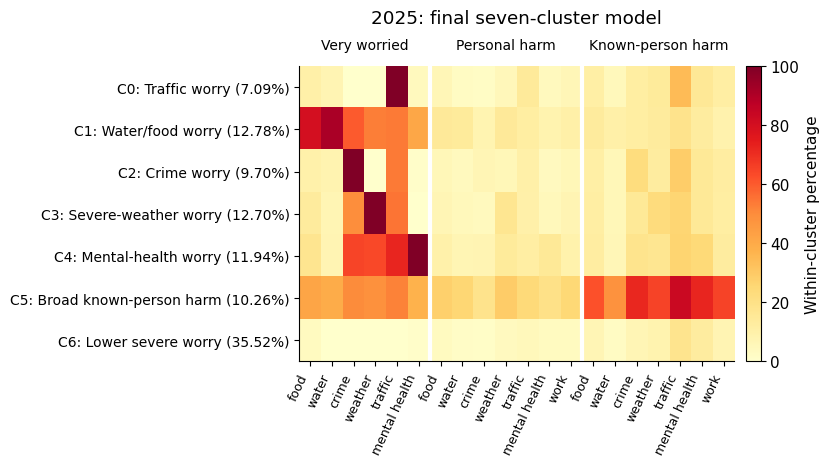

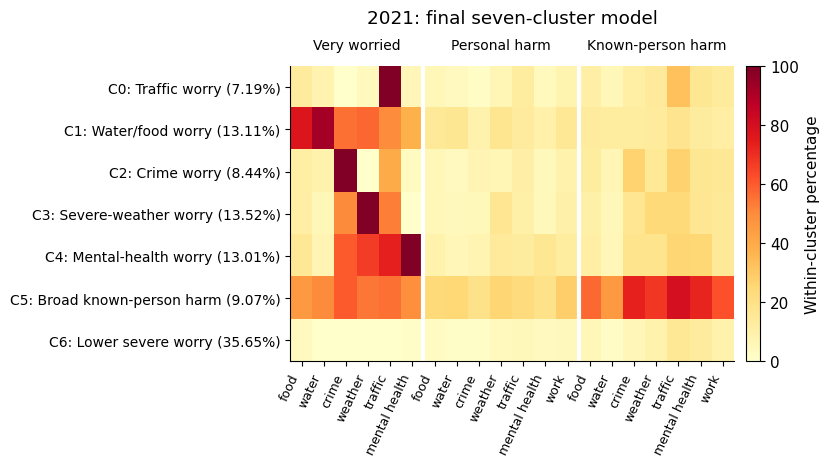

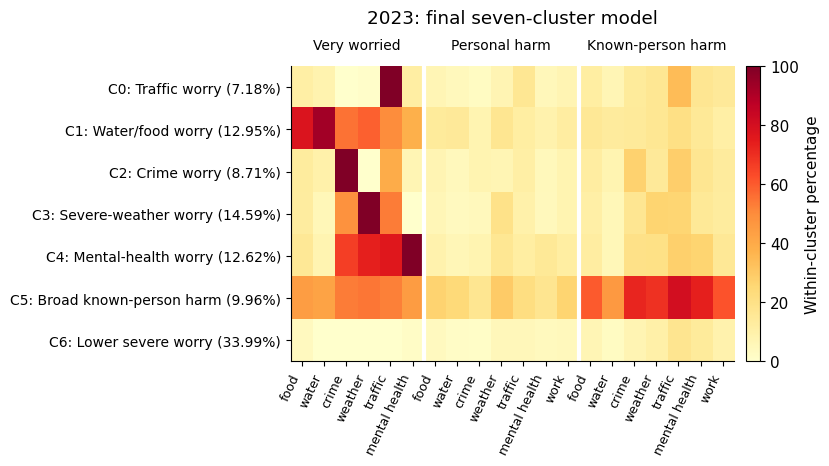

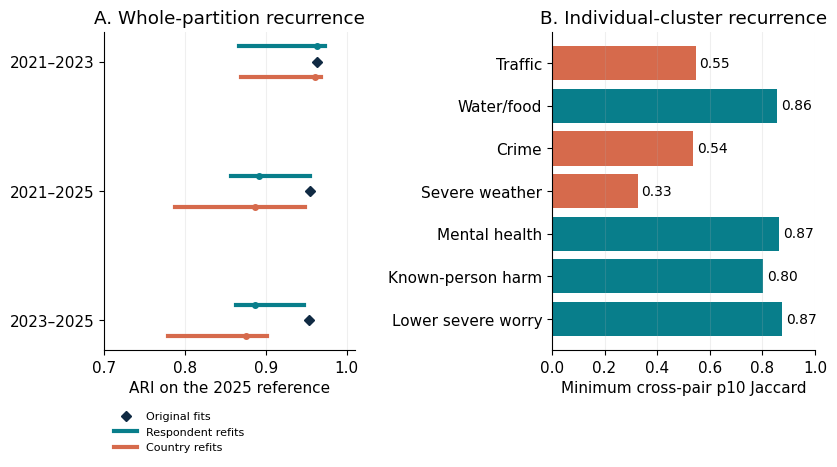

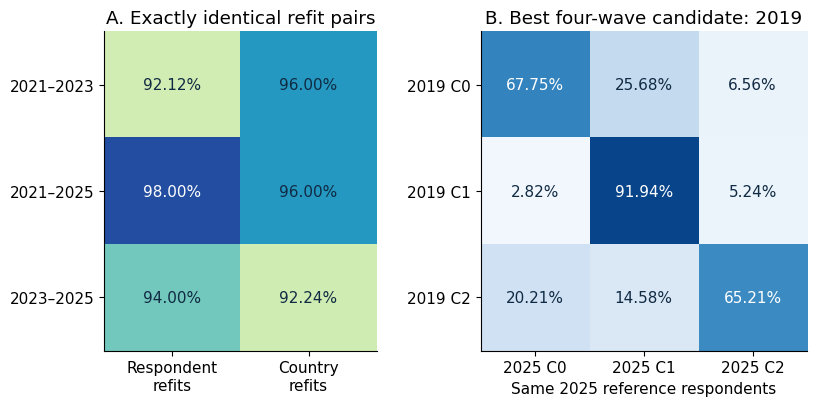

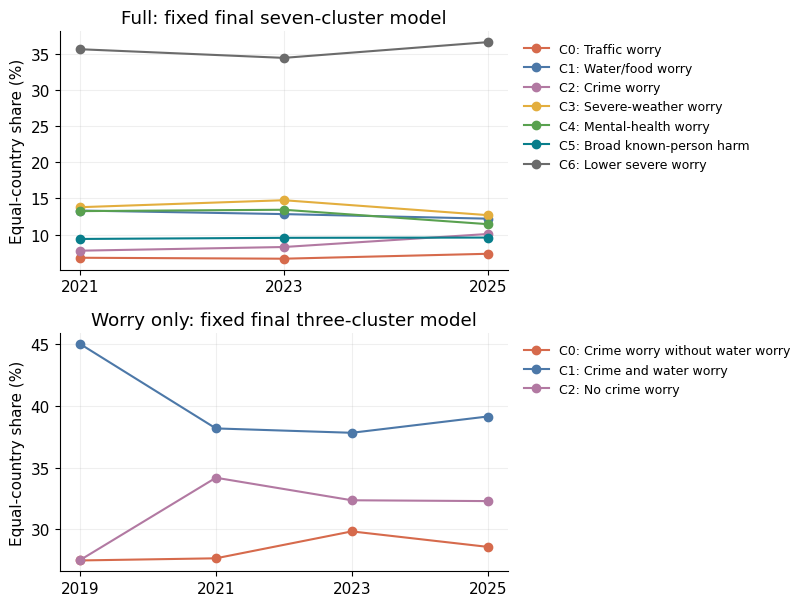

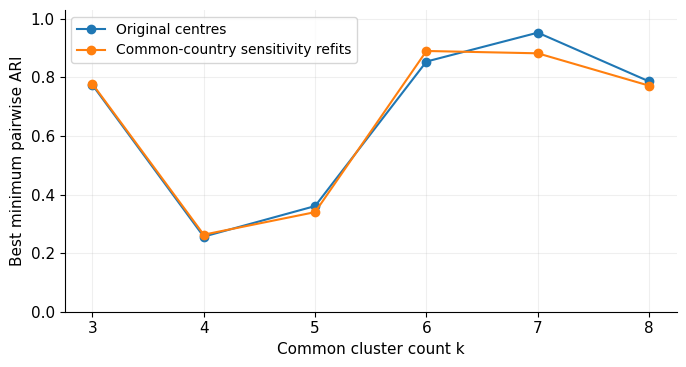

,family,earlier,cluster,change,p025,p975
0,full,2021,0,0.0055,0.0007,0.0102
1,full,2021,1,-0.0113,-0.0205,-0.0006
2,full,2021,2,0.0231,0.0157,0.0309
3,full,2021,3,-0.0110,-0.0229,0.0006
4,full,2021,4,-0.0181,-0.0283,-0.0089
5,full,2021,5,0.0019,-0.0107,0.0151
6,full,2021,6,0.0098,-0.0136,0.0315
7,full,2023,0,0.0068,0.0022,0.0117
8,full,2023,1,-0.0063,-0.0156,0.0021
9,full,2023,2,0.0180,0.0115,0.0243


In [15]:
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,
    'pdf.fonttype':42,'ps.fonttype':42})
TEAL='#087E8B';CORAL='#D66A4C';INK='#102A43'


def save_figure(fig, name):
    for extension in ['pdf','png']:
        fig.savefig(RESULTS/f'{name}.{extension}',dpi=180,bbox_inches='tight')
    plt.show()


def answer_heatmap(year, aligned=False):
    model=find_model('full',year)
    t=native_descriptions.loc[native_descriptions.family.eq('full')&
        native_descriptions.wave.eq(year)&native_descriptions.trial.eq(model['trial'])]
    selected=t.loc[((t.feature<6)&t.answer.eq(2))|((t.feature>=6)&t.answer.eq(1))]
    table=selected.pivot(index='cluster',columns='feature',values='probability')
    order=list(range(7))
    if aligned:
        order=correspondence.loc[correspondence.family.eq('full')&correspondence.wave.eq(year)].sort_values('anchor_cluster').local_cluster.tolist()
    image=table.loc[order,range(20)].to_numpy()
    shares=t.groupby('cluster').share.first()
    fig,ax=plt.subplots(figsize=(8.4,4.8))
    picture=ax.imshow(100*image,vmin=0,vmax=100,cmap='YlOrRd',aspect='auto')
    domains=[d.replace('severe_weather','weather').replace('mental_health','mental health') for d in DOMAINS]
    names=domains+[d.replace('severe_weather','weather').replace('mental_health','mental health') for d in HARM_DOMAINS]*2
    ax.set_xticks(range(20),names,rotation=65,ha='right',fontsize=9)
    ax.set_yticks(range(7),[f'C{c}: {FULL_NAMES[c]} ({100*shares[order[c]]:.2f}%)' for c in range(7)],fontsize=10)
    ax.axvline(5.5,color='white',lw=3);ax.axvline(12.5,color='white',lw=3)
    for x,text in [(2.5,'Very worried'),(9,'Personal harm'),(16,'Known-person harm')]:
        ax.text(x,-.9,text,ha='center',fontsize=10)
    ax.set_title(f'{year}: final seven-cluster model',pad=31)
    fig.colorbar(picture,ax=ax,label='Within-cluster percentage',fraction=.035,pad=.025)
    fig.tight_layout()
    return fig


save_figure(answer_heatmap(2025),'final_full_answers')
for year in [2021,2023]:
    save_figure(answer_heatmap(year,aligned=True),f'final_full_answers_{year}_aligned')

fig,axes=plt.subplots(1,2,figsize=(8.5,4.9),gridspec_kw={'width_ratios':[1,1.05]})
pairs=selected_pairs.loc[selected_pairs.family.eq('full')].sort_values(['year_a','year_b'])
for i,row in enumerate(pairs.itertuples()):
    axes[0].plot(row.ARI,i,'D',color=INK,ms=5,label='Original fits' if i==0 else None)
    for offset,test,color,label in [(-.12,'respondents',TEAL,'Respondent refits'),(.12,'countries',CORAL,'Country refits')]:
        d=distributions.loc[distributions.group.eq('full_k7')&distributions.evaluation.eq('2025')&
            distributions.metric.eq('ARI')&distributions.test.eq(test)&
            distributions.year_a.eq(row.year_a)&distributions.year_b.eq(row.year_b)].iloc[0]
        axes[0].plot([d.p10,d.p90],[i+offset,i+offset],lw=3,color=color,label=label if i==0 else None)
        axes[0].plot(d['median'],i+offset,'o',color=color,ms=4)
axes[0].set(yticks=range(3),yticklabels=[f'{r.year_a}–{r.year_b}' for r in pairs.itertuples()],
    xlim=(.7,1.01),xlabel='ARI on the 2025 reference',title='A. Whole-partition recurrence')
axes[0].invert_yaxis();axes[0].grid(axis='x',alpha=.2);axes[0].legend(loc='upper left',bbox_to_anchor=(0,-.16),fontsize=8,frameon=False,ncol=1)
t=core.sort_values('cluster');short=['Traffic','Water/food','Crime','Severe weather','Mental health','Known-person harm','Lower severe worry']
axes[1].barh(range(7),t.minimum_cross_p10,color=[CORAL if i in [0,2,3] else TEAL for i in range(7)])
axes[1].set(yticks=range(7),yticklabels=short,xlim=(0,1),xlabel='Minimum cross-pair p10 Jaccard',title='B. Individual-cluster recurrence')
axes[1].invert_yaxis();axes[1].grid(axis='x',alpha=.2)
for i,value in enumerate(t.minimum_cross_p10):axes[1].text(value+.015,i,f'{value:.2f}',va='center',fontsize=10)
fig.tight_layout(w_pad=2)
save_figure(fig,'final_cross_wave_recurrence')

fig,axes=plt.subplots(1,2,figsize=(8.3,4.2),gridspec_kw={'width_ratios':[1,1.2]})
e=exact.loc[exact.group.eq('worry_identical_later')&exact.evaluation.eq('2025')&exact.year_a.ne(exact.year_b)]
fractions=np.array([[e.loc[e.year_a.eq(a)&e.year_b.eq(b)&e.test.eq(test),'identical_fraction'].iloc[0]
    for test in ['respondents','countries']] for a,b in [(2021,2023),(2021,2025),(2023,2025)]])
axes[0].imshow(fractions,vmin=.9,vmax=1,cmap='YlGnBu',aspect='auto')
axes[0].set(xticks=[0,1],xticklabels=['Respondent\nrefits','Country\nrefits'],yticks=range(3),
    yticklabels=['2021–2023','2021–2025','2023–2025'],title='A. Exactly identical refit pairs')
for i in range(3):
    for j in range(2):axes[0].text(j,i,f'{100*fractions[i,j]:.2f}%',ha='center',va='center',color='white' if fractions[i,j]>.96 else INK)
family='common_worry';pack=references[family];mass=pack['masses'][FAMILIES[family].index(2025)]
trial=groups['worry_all4_best'][1]['2019'];old=find_model(family,2019,trial);anchor=find_model(family,2025)
x=reference_predictions[model_key(old)];y=reference_predictions[model_key(anchor)]
overlap=np.bincount(x.astype(int)*3+y,weights=mass,minlength=9).reshape(3,3)
conditional=overlap/overlap.sum(1,keepdims=True)
axes[1].imshow(conditional,vmin=0,vmax=1,cmap='Blues',aspect='auto')
axes[1].set(xticks=range(3),xticklabels=['2025 C0','2025 C1','2025 C2'],yticks=range(3),
    yticklabels=['2019 C0','2019 C1','2019 C2'],title='B. Best four-wave candidate: 2019')
axes[1].set_xlabel('Same 2025 reference respondents')
for i in range(3):
    for j in range(3):axes[1].text(j,i,f'{100*conditional[i,j]:.2f}%',ha='center',va='center',color='white' if conditional[i,j]>.6 else INK)
fig.tight_layout(w_pad=2)
save_figure(fig,'final_worry_recurrence')

fig,axes=plt.subplots(2,1,figsize=(8.2,6.2))
colours=['#D66A4C','#4C78A8','#B279A2','#E3AE3E','#59A14F','#087E8B','#6B6B6B']
for ax,family in zip(axes,['full','common_worry']):
    names=FULL_NAMES if family=='full' else WORRY_NAMES
    for c in range(7 if family=='full' else 3):
        t=fixed_frequencies.loc[fixed_frequencies.family.eq(family)&fixed_frequencies.cluster.eq(c)].sort_values('wave')
        ax.plot(t.wave,100*t.weighted_share,'o-',color=colours[c],label=f'C{c}: {names[c]}')
    ax.set_xticks(FAMILIES[family]);ax.set_ylabel('Equal-country share (%)')
    ax.set_title('Full: fixed final seven-cluster model' if family=='full' else 'Worry only: fixed final three-cluster model')
    ax.grid(alpha=.2);ax.legend(loc='upper left',bbox_to_anchor=(1.01,1),fontsize=9,frameon=False)
fig.tight_layout();save_figure(fig,'final_fixed_prevalence')

fig,ax=plt.subplots(figsize=(7,3.8))
for scope,label in [('original','Original centres'),('common_refit','Common-country sensitivity refits')]:
    t=resolution_choices.loc[resolution_choices.family.eq('full')&resolution_choices.scope.eq(scope)].sort_values('k')
    ax.plot(t.k,t.minimum_ARI,'o-',label=label)
ax.set(xticks=range(3,9),xlabel='Common cluster count k',ylabel='Best minimum pairwise ARI',ylim=(0,1.03))
ax.grid(alpha=.2);ax.legend(fontsize=10);fig.tight_layout();save_figure(fig,'alternative_resolutions')
# Country bootstrap uses national aggregates, retaining paired country identities.
country_frequency=pd.read_csv(ASSETS/'fixed_final_country_shares.csv',float_precision='round_trip')
changes=[]
for family,years in FAMILIES.items():
    countries=sorted(country_frequency.loc[country_frequency.family.eq(family)].country.unique())
    rng=np.random.default_rng(20261118);draws=rng.integers(0,len(countries),(1000,len(countries)))
    for year in years[:-1]:
        for c in range(find_model(family,2025)['k']):
            t=country_frequency.loc[country_frequency.family.eq(family)&country_frequency.cluster.eq(c)]
            before=t.loc[t.wave.eq(year)].set_index('country').loc[countries,'share'].to_numpy()
            after=t.loc[t.wave.eq(2025)].set_index('country').loc[countries,'share'].to_numpy()
            delta=after-before;low,high=np.quantile(delta[draws].mean(1),[.025,.975])
            changes.append(dict(family=family,earlier=year,cluster=c,change=delta.mean(),p025=low,p975=high))
fixed_changes=pd.DataFrame(changes)
expected=pd.read_csv(ASSETS/'fixed_final_changes.csv',float_precision='round_trip')
np.testing.assert_allclose(fixed_changes[['change','p025','p975']],expected[['change','p025','p975']],atol=1e-12,rtol=0)
expected=pd.read_csv(ASSETS/'expected_final_frequencies.csv',float_precision='round_trip')
np.testing.assert_allclose(fixed_frequencies.weighted_share,expected.weighted_share,atol=1e-12,rtol=0)
display(fixed_changes.round(4))

## 11. Complete bounded Boolean rule search

Every candidate is an OR of AND clauses with at most three condition occurrences.
After removing repetition and absorption, the shapes are one atom, two-atom AND
or OR, three-atom AND or OR, and one atom OR an AND of the other two. There are
122 + 2 choose(122,2) + 5 choose(122,3) = 1,491,084 full-model formulas, and 134,200
five-worry formulas. The supplied condition catalogues define every allowed
threshold and its original survey-question requirements.

The code evaluates these formulas exactly using weighted single, pair and triple
intersections. Inclusion-exclusion gives OR masses from those intersections.
This vectorization avoids evaluating each formula against every respondent
separately. It is exhaustive within this finite language, without a beam search.
Bit masks below only count the distinct original questions needed by a formula;
they do not change its Boolean meaning or add another model.

For each cluster, retain precision >=0.80, find maximum coverage, keep the
one-percentage-point coverage band and apply the stated deterministic ranking.
Ordered DNF serialization resolves remaining syntactic ties. Logically equivalent
formulas need not have one unique minimal Boolean representation. A missing
admissible rule is recorded explicitly without rejecting the clustering.

In [16]:
def rule_clauses(kind, i, j=-1, k=-1):
    i, j, k = int(i), int(j), int(k)
    clauses = {0: [(i,)], 1: [(i, j)], 2: [(i,), (j,)],
               3: [(i, j, k)], 4: [(i,), (j,), (k,)],
               5: [(i,), (j, k)], 6: [(j,), (i, k)], 7: [(k,), (i, j)]}[int(kind)]
    return tuple(sorted(tuple(sorted(c)) for c in clauses))

def formula_string(clauses):
    return json.dumps({'clauses': clauses}, separators=(',', ':'))

def readable_rule(clauses, conditions):
    symbols = {'known': 'K', 'personal': 'P', 'very': 'V', 'not': 'N', 'some': 'A'}
    def atom(c):
        if c['kind'] == 'count_test':
            return symbols[c['base']] + (' >= ' if c['op'] == 'ge' else ' <= ') + str(c['value'])
        return c['label']
    parts = [' AND '.join(atom(conditions[i]) for i in clause) for clause in clauses]
    return ' OR '.join('(' + text + ')' if len(clauses)>1 and len(clause)>1 else text
                       for clause, text in zip(clauses, parts))

def predicate_intersections(population, assignment, n_clusters):
    tests, weights = population['tests'], population['weights']
    pattern_labels = np.asarray(assignment, dtype=int)
    assert len(pattern_labels) == len(weights)
    n = tests.shape[1]
    triples = np.array(list(combinations(range(n), 3)), dtype=np.int16)
    one = np.zeros((n, n_clusters))
    two = np.zeros((n, n, n_clusters))
    three = np.zeros((len(triples), n_clusters))
    with threadpool_limits(limits=4):
        for cluster in range(n_clusters):
            mask = pattern_labels == cluster
            block = tests[mask].astype(float)
            one[:, cluster] = block.T @ weights[mask]
            two[:, :, cluster] = block.T @ (block * weights[mask, None])
        offset = 0
        for i in range(n-2):
            j, k = np.triu_indices(n-i-1, k=1)
            for cluster in range(n_clusters):
                mask = tests[:, i] & (pattern_labels == cluster)
                block = tests[mask, i+1:].astype(float)
                joint = block.T @ (block * weights[mask, None])
                three[offset:offset+len(j), cluster] = joint[j, k]
            offset += len(j)
    assert offset == len(triples)
    return one, two, three, triples, np.bincount(pattern_labels, weights=weights, minlength=n_clusters)

def extract_description_rules(population, assignment, model, conditions,
                              candidate_file=None, epsilon=0.01, precision_floor=0.80):
    """Exhaustive DNF search, expanded cost <=3, with the agreed deterministic selection."""
    n = len(conditions)
    one, two, three, triples, totals = predicate_intersections(population, assignment, model['k'])
    pairs = np.array(list(combinations(range(n), 2)), dtype=np.int16)
    question_bits = np.array([sum(1 << q for q in set(c['questions'])) for c in conditions])
    question_count = 1 + max(q for c in conditions for q in c['questions'])
    bit_counts = np.array([i.bit_count() for i in range(1 << question_count)])
    archives = []
    evaluated = 0

    def consider(kind, ids, intersections, cost):
        nonlocal evaluated
        # Roundoff in inclusion-exclusion can produce tiny values for empty events.
        intersections = np.where(np.abs(intersections)<1e-14, 0., intersections)
        intersections = np.minimum(np.maximum(intersections, 0.), totals)
        mass = intersections.sum(1)
        precision = np.divide(intersections, mass[:, None], out=np.zeros_like(intersections),
                              where=mass[:, None]>0)
        coverage = intersections / totals
        row, cluster = np.nonzero((mass[:, None]>0) & (precision>=precision_floor-1e-12))
        evaluated += len(ids)
        if not len(row):
            return
        selected = ids[row]
        q = bit_counts[np.bitwise_or.reduce(question_bits[selected], axis=1)]
        clauses = [rule_clauses(kind, *v) for v in selected]
        archives.append(pd.DataFrame(dict(cluster=cluster, kind=kind, i=selected[:,0],
            j=selected[:,1] if selected.shape[1]>1 else -1,
            k_atom=selected[:,2] if selected.shape[1]>2 else -1, cost=cost, questions=q,
            precision=precision[row,cluster], coverage=coverage[row,cluster],
            selected_mass=mass[row], true_mass=intersections[row,cluster],
            canonical_formula=[formula_string(c) for c in clauses])))

    consider(0, np.arange(n).reshape(-1,1), one.copy(), 1)
    a,b = pairs.T
    consider(1, pairs, two[a,b].copy(), 2)
    consider(2, pairs, one[a]+one[b]-two[a,b], 2)
    i,j,k = triples.T
    consider(3, triples, three.copy(), 3)
    consider(4, triples, one[i]+one[j]+one[k]-two[i,j]-two[i,k]-two[j,k]+three, 3)
    consider(5, triples, one[i]+two[j,k]-three, 3)
    consider(6, triples, one[j]+two[i,k]-three, 3)
    consider(7, triples, one[k]+two[i,j]-three, 3)
    assert evaluated == n + 2*comb(n,2) + 5*comb(n,3)
    candidates = pd.concat(archives, ignore_index=True) if archives else pd.DataFrame(columns=['cluster'])
    if candidate_file is not None:
        candidates.to_csv(candidate_file, index=False, compression='gzip')
    selected_rules = []
    for cluster in range(model['k']):
        group = candidates.loc[candidates.cluster.eq(cluster)].copy()
        common = dict(wave=model['year'], trial=model['trial'], model_id=model['model_id'],
                      n_clusters=model['k'], cluster=cluster, formulas_evaluated=evaluated,
                      admissible_candidates=len(group), epsilon=epsilon, precision_floor=precision_floor)
        if group.empty:
            # A missing compact description does not remove an otherwise passing clustering.
            selected_rules.append(dict(common, status='no admissible rule under the declared budget'))
            continue
        maximum = group.coverage.max()
        band = group.loc[group.coverage>=maximum-epsilon-1e-12].copy()
        band['_p'] = band.precision.round(12)
        band['_r'] = band.coverage.round(12)
        best = band.sort_values(['cost','_p','_r','questions','canonical_formula'],
                               ascending=[True,False,False,True,True]).iloc[0]
        record = best.drop(labels=['_p','_r']).to_dict()
        clauses = rule_clauses(record['kind'],record['i'],record['j'],record['k_atom'])
        selected_rules.append(dict(record, **{key:value for key,value in common.items() if key!='cluster'},
                                   status='selected', best_coverage=maximum,
                                   rule=readable_rule(clauses, conditions)))
    return pd.DataFrame(selected_rules)


def search_rules_for_model(model):
    pack=native[model['family'],model['year']]
    tests=condition_masks(pack['answers'],conditions[model['family']],model['family'])
    population=dict(tests=tests,weights=pack['mass'])
    return extract_description_rules(population,native_predictions[model_key(model)],model,
                                     conditions[model['family']])


if REGENERATE_RULES:
    destination=RESULTS/('new_rule_search_'+datetime.now().strftime('%Y%m%d_%H%M%S'))
    destination.mkdir(exist_ok=False)
    for model in models:
        if model['scope']!='original':continue
        selected=search_rules_for_model(model)
        selected.to_csv(destination/f'{model["family"]}_{model["year"]}_{model["trial"]}.csv',index=False)

## 12. Country summaries and the visualization

The website uses the same selected model definitions as this notebook. For each
country, normalize eligible respondents' WGT to one and calculate cluster shares
and original-answer category probabilities. The new cross-wave models use only
their development countries; they receive no newly claimed held-out assessment.
The preserved historical 2023 pages retain their own original populations.

Cluster-share distance is Hellinger distance. Original-answer distance averages
question-wise total variation; for full models, combine worry, personal harm and
known-person harm with the model's alpha. A fixed 2025 median distance supplies
the colour denominator inside each input family and distance component. The
country-colour overview projects square-root cluster shares into two principal
coordinates. This is a display approximation, not another respondent clustering.

Country pairs reuse countries. The descriptive income correlations below do not
assume independent pairs or support a causal interpretation. We do not copy the
old models' uncertainty or permutation results onto these newly selected models.

In [17]:
def country_distances(shares, probabilities, family, alpha):
    n=6 if family=='full' else 5
    output={'clusters':squareform(pdist(np.sqrt(shares)))/np.sqrt(2)}
    output['worry']=sum(np.abs(probabilities[:,None,3*j:3*j+3]-
        probabilities[None,:,3*j:3*j+3]).sum(2)/(2*n) for j in range(n))
    if family=='full':
        output['personal']=np.abs(probabilities[:,None,3*n:3*n+7]-probabilities[None,:,3*n:3*n+7]).mean(2)
        output['known']=np.abs(probabilities[:,None,3*n+7:]-probabilities[None,:,3*n+7:]).mean(2)
        output['responses']=alpha*output['worry']+(1-alpha)*(output['personal']+output['known'])/2
    else:
        output['responses']=output['worry'].copy()
    return output


def country_embedding(shares):
    root=np.sqrt(shares)/np.sqrt(2);root-=root.mean(0)
    with threadpool_limits(limits=1):
        u,s,v=np.linalg.svd(root,full_matrices=False)
    coordinates=u[:,:2]*s[:2]
    for j in range(2):
        if coordinates[np.flatnonzero(np.abs(coordinates[:,j])>1e-12)[0],j]<0:coordinates[:,j]*=-1
    exact=pdist(np.sqrt(shares))/np.sqrt(2);approx=pdist(coordinates)
    return dict(coordinates=coordinates.tolist(),variance=float((s[:2]**2).sum()/(s**2).sum()),
        rankCorrelation=float(spearmanr(exact,approx).statistic),
        stress=float(np.sqrt(((exact-approx)**2).sum()/(exact**2).sum())))


def country_summaries(countries, distances):
    n=len(countries);a,b=np.triu_indices(n,1)
    region=np.array([c['regionId'] for c in countries]);income=np.array([c['income'] for c in countries])
    same=region[a]==region[b];valid=np.isin(income,[1,2,3,4]);classified=valid[a]&valid[b]
    result={}
    for key,matrix in distances.items():
        values=matrix[a,b];neighbours=[]
        for i in range(n):
            others=[j for j in range(n) if j!=i]
            neighbours.append(min(others,key=lambda j:(matrix[i,j],countries[j]['iso'])))
        cells=[]
        for i in [1,2,3,4]:
            row=[]
            for j in [1,2,3,4]:
                mask=((income[a]==i)&(income[b]==j))|((income[a]==j)&(income[b]==i))
                row.append(dict(mean=float(values[mask].mean()) if mask.any() else None,pairs=int(mask.sum())))
            cells.append(row)
        rho=spearmanr(np.abs(income[a[classified]]-income[b[classified]]),values[classified]).statistic
        result[key]=dict(countries=n,pairs=len(values),median=float(np.median(values)),
            same_region_mean=float(values[same].mean()),different_region_mean=float(values[~same].mean()),
            nearest_same_region=float(np.mean(region==region[neighbours])),random_peer_same_region=float(same.mean()),
            classified_countries=int(valid.sum()),income=dict(rho=float(rho),unrestricted=None,within_regions=None),income_cells=cells)
    x=distances['clusters'];y=distances['responses']
    nx=[min([j for j in range(n) if j!=i],key=lambda j:(x[i,j],countries[j]['iso'])) for i in range(n)]
    ny=[min([j for j in range(n) if j!=i],key=lambda j:(y[i,j],countries[j]['iso'])) for i in range(n)]
    result['comparison']=dict(distance_rank_spearman=float(spearmanr(x[a,b],y[a,b]).statistic),nearest_agreement=float(np.mean(np.array(nx)==ny)))
    return result


def aggregate_country_answers(answers, labels, wgt, iso, metadata, model, names):
    n=6 if model['family']=='full' else 5
    countries=[];shares=[];probabilities=[]
    for code in sorted(set(iso)):
        mask=iso==code;weight=wgt[mask]/wgt[mask].sum();block=answers[mask]
        countries.append(dict(metadata[code],respondents=int(mask.sum()),split='train'))
        countries[-1]['retention']=mask.sum()/countries[-1]['totalRespondents']
        shares.append(np.bincount(labels[mask],weights=weight,minlength=model['k']))
        probabilities.append([weight[block[:,j]==a].sum() for j in range(n) for a in range(3)]+
            ([weight[block[:,j]==1].sum() for j in range(n,20)] if model['family']=='full' else []))
    shares=np.array(shares);probabilities=np.array(probabilities)
    distances=country_distances(shares,probabilities,model['family'],model.get('alpha',1))
    summary=country_summaries(countries,distances)
    return dict(key=f'{model["family"]}_{model["year"]}',family=model['family'],year=model['year'],
        id=model['model_id'],trial=model['trial'],k=model['k'],alpha=model.get('alpha',1),names=names,
        worryDomains=DOMAINS if model['family']=='full' else [d for d in DOMAINS if d!='traffic'],
        countries=countries,shares=shares.tolist(),probabilities=probabilities.tolist(),embedding=country_embedding(shares),
        summaries={'all':summary,'development':summary},nearest_uncertainty=[],scope='development',
        role='independent_2019_alternative' if model['year']==2019 else 'paper_primary',heldoutAssessed=False)


# These are national aggregate tables, without respondent-linked observations.
country_data=json.loads((ASSETS/'country_aggregates.json').read_text())
country_results=[]
for key,m in country_data['models'].items():
    shares=np.asarray(m['shares']);probabilities=np.asarray(m['probabilities'])
    np.testing.assert_allclose(shares.sum(1),1,atol=1e-12,rtol=0)
    distances=country_distances(shares,probabilities,m['family'],m['alpha'])
    summary=country_summaries(m['countries'],distances)
    for metric,table in summary.items():
        for column in ['median','nearest_same_region'] if metric!='comparison' else ['distance_rank_spearman','nearest_agreement']:
            np.testing.assert_allclose(table[column],m['summaries']['all'][metric][column],atol=1e-12,rtol=0)
    country_results.append(dict(model=key,countries=len(m['countries']),clusters=m['k'],
        cluster_response_distance_correlation=summary['comparison']['distance_rank_spearman']))
display(pd.DataFrame(country_results).round(4))

,model,countries,clusters,cluster_response_distance_correlation
0,full_2021,96,7,0.8739
1,full_2023,113,7,0.8742
2,full_2025,111,7,0.8705
3,common_worry_2019,114,3,0.7607
4,common_worry_2021,96,3,0.7362
5,common_worry_2023,113,3,0.6925
6,common_worry_2025,111,3,0.6647


## 13. Complete optional fitting and confirmation

The frozen results above need no new fitting. For a new reproduction or extension,
supply the separately obtained source CSVs and retain the published country split.
The functions below implement preprocessing, weighted K-means, both 80% subsampling
procedures, pilot evaluation, shortlist sealing, fresh confirmation, all acceptance
decisions and descriptions of every passing setting. Nothing is hidden in a script.

The historical TPE proposals are explicit catalogue values, not an executable
optimizer dependency. This code re-evaluates that entire finite catalogue. A new
fit is a new fitted model: platform, source ordering and random-number details can
change results. It does not replace the original centres, immutable confirmations
or held-out findings. Replaying historical adaptive proposal generation would
require its original optimizer/runtime, which is not imported here.

The expensive switch is off. New results go into a dated directory. No held-out
responses are read for fitting. The declared filters do not change if a preferred
candidate fails. To investigate another parameter design, edit a copy of the
catalogue and identify that experiment separately.

In [18]:
SURVEY_FILES={y:Path(f'private_surveys/WRP_{y}.csv') for y in [2019,2021,2023,2025]}


def load_development_survey(family, year):
    raw=pd.read_csv(SURVEY_FILES[year],float_precision='round_trip')
    registry=pd.read_csv(ASSETS/f'country_split_{family}_{year}.csv')
    codes=registry.loc[registry.country_split.eq('train'),'COUNTRY_ISO3']
    raw=raw.loc[raw.COUNTRY_ISO3.isin(codes)].reset_index(drop=True)
    if 'WPID_RANDOM' in raw:assert raw.WPID_RANDOM.is_unique
    frame,answers=recode_survey(raw,family,year)
    assert set(frame.COUNTRY_ISO3)==set(codes)
    return frame,answers


def subsampling_plans(frame, seed, repetitions):
    rng=np.random.default_rng(seed)
    countries=frame[['COUNTRY_ISO3','GlobalRegion','CountryIncomeLevel']].drop_duplicates()
    assert countries.COUNTRY_ISO3.is_unique
    strata=list(countries.groupby(['GlobalRegion','CountryIncomeLevel'],sort=True,dropna=False))
    available=np.array([len(g) for _,g in strata]);quota=np.maximum(1,np.floor(.8*available).astype(int))
    target=round(.8*len(countries))
    assert len(strata)<=target, 'Too many strata for the declared country fraction.'
    while quota.sum()<target:
        score=np.where(quota<available,.8*available-quota,-np.inf);quota[score.argmax()]+=1
    while quota.sum()>target:
        score=np.where(quota>1,quota-.8*available,-np.inf);quota[score.argmax()]-=1
    indices={c:np.flatnonzero(frame.COUNTRY_ISO3.to_numpy()==c) for c in sorted(frame.COUNTRY_ISO3.unique())}
    plans={'respondents':[],'countries':[]}
    for repeat in range(repetitions):
        plans['respondents'].append(np.concatenate([rng.choice(ids,round(.8*len(ids)),replace=False) for ids in indices.values()]))
        selected=[]
        for i,(_,group) in enumerate(strata):selected.extend(rng.choice(sorted(group.COUNTRY_ISO3),quota[i],replace=False))
        plans['countries'].append(np.flatnonzero(frame.COUNTRY_ISO3.isin(selected).to_numpy()))
    return plans


def fit_weighted(frame, answers, model, indices, seed):
    weights=country_weights(frame.iloc[indices])
    values=matrix(answers[indices],model,model['family'])
    if model['family']=='common_worry':
        unique,inverse=np.unique(values,axis=0,return_inverse=True)
        mass=np.bincount(inverse,weights=weights);values=unique;weights=mass
    with threadpool_limits(limits=1):
        fitted=KMeans(n_clusters=model['k'],n_init=20,max_iter=300,
            tol=0. if model['family']=='common_worry' else 1e-4,random_state=seed)
        fitted.fit(values,sample_weight=weights)
    return fitted.cluster_centers_


def matched_jaccards(reference, other, weights, k):
    cross=np.bincount(reference.astype(int)*k+other,weights=weights,minlength=k*k).reshape(k,k)
    a,b=linear_sum_assignment(-cross);hit=cross[a,b]
    result=np.zeros(k);result[a]=hit/(cross.sum(1)[a]+cross.sum(0)[b]-hit)
    return result


def evaluate_candidate(frame, answers, family, year, q, alpha, k, phase, plans, reference_centres):
    model=dict(family=family,year=year,k=int(k),q=float(q),t=1/float(q),alpha=float(alpha),scope='new')
    model['trial']=f'k{k}_'+hashlib.sha256(json.dumps([float(q),float(alpha),int(k)]).encode()).hexdigest()[:16]
    model['model_id']=f'new_{year}:{model["trial"]}'
    model['centres']=np.asarray(reference_centres).tolist()
    pack=aggregate_patterns(frame,answers);geometry=matrix(pack['answers'],model,family)
    reference=cdist(geometry,reference_centres).argmin(1)
    shares=np.bincount(reference,weights=pack['mass'],minlength=k)
    row=dict(family=family,wave=year,trial=model['trial'],k=k,q=q,t=1/q,alpha=alpha,phase=phase,
        largest_share=shares.max(),dominance=k*shares.max(),structural_pass=len(np.unique(reference))==k and shares.max()<=.4 and k*shares.max()<3)
    if not row['structural_pass']:
        return dict(row,status='structurally ineligible',score=np.nan,minimum_median=np.nan),model,[]
    matching=[];base_seed=year*1000000+(102800 if phase=='pilot' else 112800)
    for test,subsamples in plans.items():
        labels=[]
        for repeat,ids in enumerate(subsamples):
            centres=fit_weighted(frame,answers,model,ids,base_seed+repeat)
            prediction=cdist(geometry,centres).argmin(1);labels.append(prediction)
            if phase=='confirmation':
                recovery=matched_jaccards(reference,prediction,pack['mass'],k)
                matching.extend(dict(test=test,repeat=repeat,cluster=c,jaccard=float(v)) for c,v in enumerate(recovery))
        scores=[metrics(a,b,pack['counts'],pack['mass'],k,k)['ARI'] for a,b in combinations(labels,2)]
        row[test+'_median']=np.median(scores);row[test+'_p10']=np.quantile(scores,.1)
    row['score']=min(row['respondents_p10'],row['countries_p10'])
    row['minimum_median']=min(row['respondents_median'],row['countries_median'])
    return dict(row,status='complete'),model,matching


def confirmed_pass(row):
    return (row['status']=='complete' and row['structural_pass'] and row['largest_share']<=.4
            and row['dominance']<3 and all(row[key]>=.8 for key in quality_columns))


def refit_catalogue(family, year, destination):
    frame,answers=load_development_survey(family,year)
    destination.mkdir(parents=True,exist_ok=False)
    pilot_plans=subsampling_plans(frame,year*1000000+102700,10)
    confirmation_plans=subsampling_plans(frame,year*1000000+112700,50)
    settings=catalogue.loc[catalogue.family.eq(family)&catalogue.wave.eq(year),['k','q','alpha']].copy()
    if family=='common_worry':settings['alpha']=1.
    settings=settings.drop_duplicates().sort_values(['k','q','alpha'])
    centres={};pilots=[]
    for r in settings.itertuples():
        model=dict(family=family,k=int(r.k),q=float(r.q),alpha=float(r.alpha))
        fitted=fit_weighted(frame,answers,model,np.arange(len(frame)),year*10000+1027)
        centres[int(r.k),float(r.q),float(r.alpha)]=fitted
        row,_,_=evaluate_candidate(frame,answers,family,year,r.q,r.alpha,int(r.k),'pilot',pilot_plans,fitted)
        pilots.append(row)
    pilots=pd.DataFrame(pilots);pilots.to_csv(destination/'pilot_results.csv',index=False)
    eligible=pilots.loc[pilots.status.eq('complete')&pilots.structural_pass].copy()
    eligible['central_distance']=(eligible.q-.5)**2+((eligible.alpha-.5)**2 if family=='full' else 0)
    eligible=eligible.sort_values(['score','minimum_median','central_distance','q','alpha'],ascending=[False,False,True,True,True])
    shortlist=eligible.groupby('k',sort=True).head(2)[['k','q','alpha']]
    if family=='full' and year==2023:
        shortlist=pd.concat([shortlist,pd.DataFrame([dict(k=4,q=.5,alpha=.5),dict(k=8,q=1/3,alpha=.75)])]).drop_duplicates()
    # Seal parameter choices before inspecting any new confirmation result.
    shortlist.to_csv(destination/'shortlist_before_confirmation.csv',index=False)
    confirmed=[];passing_models=[];rule_tables=[];cluster_tables=[]
    pack=aggregate_patterns(frame,answers)
    tests=condition_masks(pack['answers'],conditions[family],family)
    for r in shortlist.itertuples():
        key=int(r.k),float(r.q),float(r.alpha)
        fitted=centres.get(key)
        if fitted is None:
            fitted=fit_weighted(frame,answers,dict(family=family,k=key[0],q=key[1],alpha=key[2]),np.arange(len(frame)),year*10000+1027)
        row,model,matching=evaluate_candidate(frame,answers,family,year,r.q,r.alpha,int(r.k),'confirmation',confirmation_plans,fitted)
        row['confirmed_passing']=confirmed_pass(row);confirmed.append(row)
        if not row['confirmed_passing']:continue
        passing_models.append(model)
        labels=cdist(matrix(pack['answers'],model,family),fitted).argmin(1)
        cluster_tables.append(describe_patterns(pack,labels,model))
        selected=extract_description_rules(dict(tests=tests,weights=pack['mass']),labels,model,conditions[family])
        selected['family']=family;rule_tables.append(selected)
        pd.DataFrame(matching).to_csv(destination/f'{model["trial"]}_cluster_recovery.csv',index=False)
    pd.DataFrame(confirmed).to_csv(destination/'all_confirmation_results.csv',index=False)
    (destination/'passing_models.json').write_text(json.dumps(passing_models,indent=2)+'\n')
    if rule_tables:pd.concat(rule_tables,ignore_index=True).to_csv(destination/'all_passing_rules.csv',index=False)
    if cluster_tables:pd.concat(cluster_tables,ignore_index=True).to_csv(destination/'all_passing_descriptions.csv',index=False)
    return passing_models


if REFIT_CANDIDATE_CATALOGUE:
    destination=RESULTS/('new_catalogue_fits_'+datetime.now().strftime('%Y%m%d_%H%M%S'))
    for family,years in FAMILIES.items():
        for year in years:
            refit_catalogue(family,year,destination/f'{family}_{year}')

## 14. Reproducible evidence and the paper's conclusions

The main findings concern the independently fitted seven-cluster full set and
the identical later-wave worry-only set. Other passing settings remain within-
wave suitable alternatives and fitting-frame sensitivities. They are not silently
discarded, nor assumed to be equally probable scientific models.

All exported tables retain family, wave, setting, scope and evaluation population.
The original 2025 benchmark and 2023 T5 retain their exact provenance. Their
held-out evidence does not transfer automatically to the final jointly selected
models. No claim of natural population types, measurement invariance, individual
transitions or causation follows from the cross-wave agreement.

The code produces a recurring core and its limits in one transparent account.
The four stronger full-model clusters cover about 70% of the primary reference,
while finer traffic, crime and weather divisions vary more. The later-wave worry
partition gives a complementary coarse summary. Including 2019 exposes the limit
of recurrence rather than a result to remove from the report.

The outputs below are the numerical companion to the paper and website. New
optional fitting results use dated folders and do not overwrite these sources.

In [19]:
exports=dict(eligibility=eligibility,all_confirmation_results=confirmation,
    all_accepted_settings=accepted,all_native_descriptions=native_descriptions,
    all_candidate_pairs=all_pairs,all_resolution_choices=resolution_choices,
    principal_point_comparisons=selected_pairs,conditional_refit_distributions=distributions,
    exact_partition_frequencies=exact,seven_cluster_recurrence=core,
    all_cluster_rules=rules,primary_cluster_rules=primary_rules,
    fixed_final_frequencies=fixed_frequencies,fixed_final_changes=fixed_changes,
    final_correspondence=correspondence,unchanged_rule_transfer=rule_transfer)
for name,table in exports.items():table.to_csv(RESULTS/f'{name}.csv',index=False)
receipt=dict(original_accepted_settings=len(accepted),original_cluster_descriptions=len(rules),
    principal_full_clusters=7,principal_worry_clusters=3,reference_model_definitions=len(models),
    scope_pair_population_comparisons=len(all_pairs),new_scientific_fits=0,
    heldout_risk_responses_used=False,all_rule_scores_verified=True,
    principal_refit_distributions_recalculated=RECALCULATE_DISTRIBUTIONS)
(RESULTS/'verification.json').write_text(json.dumps(receipt,indent=2)+'\n')
display(receipt)

{'original_accepted_settings': 47,
 'original_cluster_descriptions': 259,
 'principal_full_clusters': 7,
 'principal_worry_clusters': 3,
 'reference_model_definitions': 94,
 'scope_pair_population_comparisons': 3310,
 'new_scientific_fits': 0,
 'heldout_risk_responses_used': False,
 'all_rule_scores_verified': True,
 'principal_refit_distributions_recalculated': True}